In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression

from sklearn.svm import SVC

from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_csv("heart_disease_combined.csv")
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,source
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,cleveland
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1,cleveland
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,cleveland
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,cleveland
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,cleveland
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,54.0,0.0,4.0,127.0,333.0,1.0,1.0,154.0,0.0,0.0,NaN,NaN,NaN,1,va
916,62.0,1.0,1.0,NaN,139.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0,va
917,55.0,1.0,4.0,122.0,223.0,1.0,1.0,100.0,0.0,0.0,NaN,NaN,6.0,1,va
918,58.0,1.0,4.0,NaN,385.0,1.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,0,va


In [3]:
df.head(5)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,source
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,cleveland
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1,cleveland
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,cleveland
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,cleveland
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,cleveland


In [4]:
df.tail(6)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,source
914,46.0,1.0,4.0,134.0,310.0,0.0,0.0,126.0,0.0,0.0,NaN,NaN,3.0,1,va
915,54.0,0.0,4.0,127.0,333.0,1.0,1.0,154.0,0.0,0.0,NaN,NaN,NaN,1,va
916,62.0,1.0,1.0,NaN,139.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0,va
917,55.0,1.0,4.0,122.0,223.0,1.0,1.0,100.0,0.0,0.0,NaN,NaN,6.0,1,va
918,58.0,1.0,4.0,NaN,385.0,1.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,0,va
919,62.0,1.0,2.0,120.0,254.0,0.0,2.0,93.0,1.0,0.0,NaN,NaN,NaN,1,va


In [5]:
df.sample(6)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,source
776,53.0,1.0,4.0,154.0,0.0,NaN,1.0,140.0,1.0,1.5,2.0,NaN,NaN,1,va
713,69.0,1.0,4.0,135.0,0.0,0.0,0.0,130.0,0.0,0.0,2.0,NaN,6.0,1,switzerland
515,50.0,0.0,3.0,140.0,288.0,0.0,0.0,140.0,1.0,0.0,NaN,NaN,7.0,1,hungarian
719,74.0,1.0,2.0,145.0,0.0,NaN,1.0,123.0,0.0,1.3,1.0,NaN,NaN,1,switzerland
547,54.0,1.0,4.0,140.0,NaN,0.0,0.0,118.0,1.0,0.0,NaN,NaN,NaN,1,hungarian
905,61.0,1.0,3.0,NaN,284.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1,va


In [7]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target', 'source'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       920 non-null    float64
 1   sex       920 non-null    float64
 2   cp        920 non-null    float64
 3   trestbps  861 non-null    float64
 4   chol      890 non-null    float64
 5   fbs       830 non-null    float64
 6   restecg   918 non-null    float64
 7   thalach   865 non-null    float64
 8   exang     865 non-null    float64
 9   oldpeak   858 non-null    float64
 10  slope     611 non-null    float64
 11  ca        309 non-null    float64
 12  thal      434 non-null    float64
 13  target    920 non-null    int64  
 14  source    920 non-null    str    
dtypes: float64(13), int64(1), str(1)
memory usage: 107.9 KB


In [9]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,920.000000,920.000000,920.000000,861.000000,890.000000,830.000000,918.000000,865.000000,865.000000,858.000000,611.000000,309.000000,434.000000,920.000000
mean,53.510870,0.789130,3.250000,132.132404,199.130337,0.166265,0.604575,137.545665,0.389595,0.878788,1.770867,0.676375,5.087558,0.553261
std,9.424685,0.408148,0.930969,19.066070,110.780810,0.372543,0.805827,25.926276,0.487941,1.091226,0.619256,0.935653,1.919075,0.497426
min,28.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,-2.600000,1.000000,0.000000,3.000000,0.000000
25%,47.000000,1.000000,3.000000,120.000000,175.000000,0.000000,0.000000,120.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,54.000000,1.000000,4.000000,130.000000,223.000000,0.000000,0.000000,140.000000,0.000000,0.500000,2.000000,0.000000,6.000000,1.000000
75%,60.000000,1.000000,4.000000,140.000000,268.000000,0.000000,1.000000,157.000000,1.000000,1.500000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,603.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000


In [10]:
df.shape

(920, 15)

In [15]:
df.duplicated().sum()

np.int64(2)

In [17]:
df = df.drop_duplicates()

In [13]:
df.isnull().sum()

age           0
sex           0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalach      55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
target        0
source        0
dtype: int64

In [14]:
df.isnull().sum().sum()

np.int64(1759)

In [18]:
numerical_columns = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

In [19]:
categorical_columns = ['sex', 'cp', 'fbs', 'restecg',
                       'exang', 'slope', 'ca', 'thal']

In [22]:
df = df.drop('source', axis=1)

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [105]:
df.dropna()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,1
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,1
301,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.0,3.0,1
508,47.0,1.0,4.0,150.0,226.0,0.0,0.0,98.0,1.0,1.5,2.0,0.0,7.0,1


In [106]:
df = df.dropna()

Visualizing Heart Disease Rate by Gender

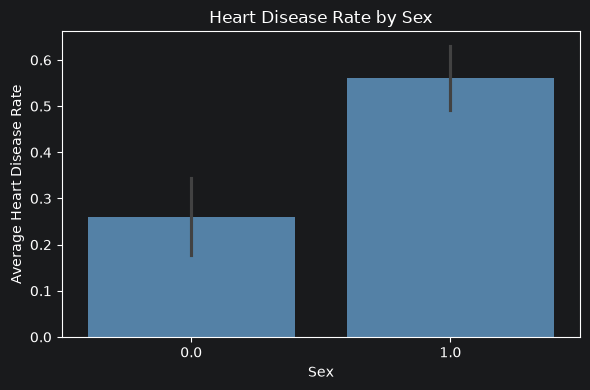

In [110]:
plt.figure(figsize=(6, 4))
sns.barplot(x='sex', y='target', data=df, color='steelblue')
plt.title('Heart Disease Rate by Sex')
plt.ylabel('Average Heart Disease Rate')
plt.xlabel('Sex')
plt.tight_layout()
plt.show()

Heart Disease

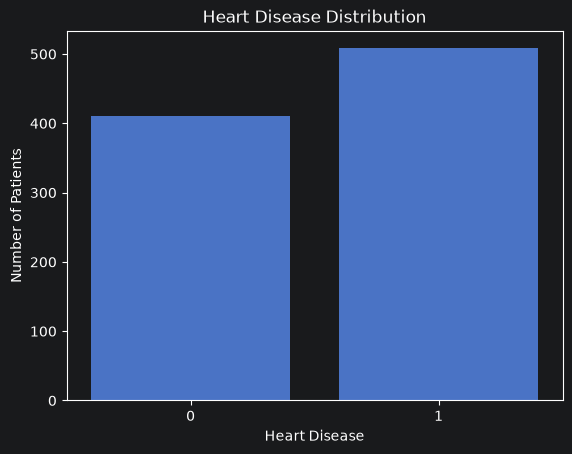

In [23]:
sns.countplot(x='target', data=df)

plt.title('Heart Disease Distribution')
plt.xlabel('Heart Disease')
plt.ylabel('Number of Patients')

plt.show()

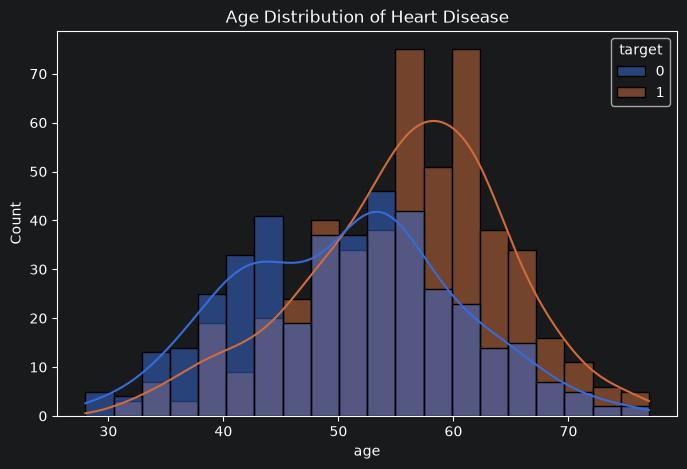

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='age', hue='target',
             bins=20, kde=True)

plt.title('Age Distribution of Heart Disease')
plt.show()

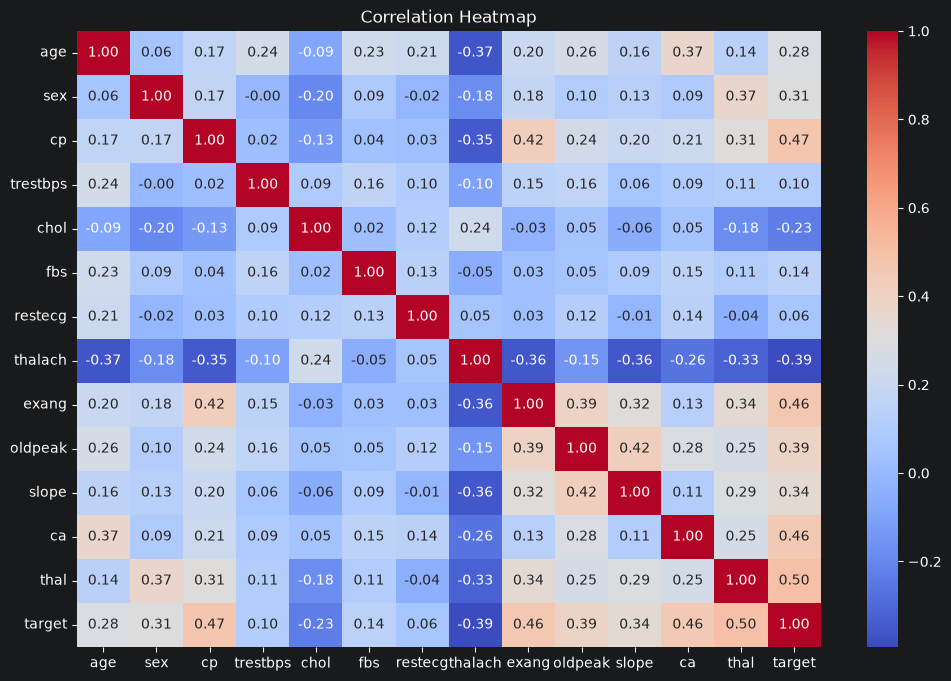

In [25]:
plt.figure(figsize=(12, 8))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm',
            fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

In [99]:
X = df.drop('target', axis=1)

y = df['target']

Train-Test Split (80% Train, 20% Test)

In [63]:
train_data = df.sample(frac=0.8, random_state=42)

test_data = df.drop(train_data.index)

In [66]:
X_train = train_data.drop('target', axis=1)

y_train = train_data['target']

X_test = test_data.drop('target', axis=1)

y_test = test_data['target']

Standardizing Train and Test Data

In [109]:
X_train = (X_train - X_train.mean()) / X_train.std()

X_test = (X_test - train_data.drop('target', axis=1).mean()) / train_data.drop('target', axis=1).std()

In [107]:
X = pd.get_dummies(X, drop_first=True)

Encoding Target Variable (y) using LabelEncoder

In [37]:
y = LabelEncoder().fit_transform(y)

Checking the Shape of Train and Test Sets

In [61]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(734, 13)
(734,)
(184, 13)
(184,)


In [54]:
X_train.isnull().sum()

age           0
sex           0
cp            0
trestbps     45
chol         22
fbs          73
restecg       2
thalach      41
exang        41
oldpeak      47
slope       248
ca          490
thal        379
dtype: int64

In [112]:
X_train.isnull().sum().sum()

np.int64(0)

Handling Missing Values (Median for Numerical, Mode for Categorical)

In [135]:
numerical_columns = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

categorical_columns = ['sex', 'cp', 'fbs', 'restecg',
                       'exang', 'slope', 'ca', 'thal']

for column in numerical_columns:
    X_train[column] = X_train[column].fillna(X_train[column].median())
    X_test[column] = X_test[column].fillna(X_train[column].median())

for column in categorical_columns:
    X_train[column] = X_train[column].fillna(X_train[column].mode()[0])
    X_test[column] = X_test[column].fillna(X_train[column].mode()[0])

Logistic Regression Model & Accuracy

In [57]:
logreg = LogisticRegression(max_iter=1000, random_state=42)

logreg.fit(X_train, y_train)

y_pred_logreg = logreg.predict(X_test)

print("Logistic Regression Accuracy:", logreg.score(X_test, y_test))

Logistic Regression Accuracy: 0.7989130434782609


In [71]:
y_pred_logreg = logreg.predict(X_test)

In [73]:
print("Actual:", len(y_test))
print("Predicted:", len(y_pred_logreg))

Actual: 60
Predicted: 60


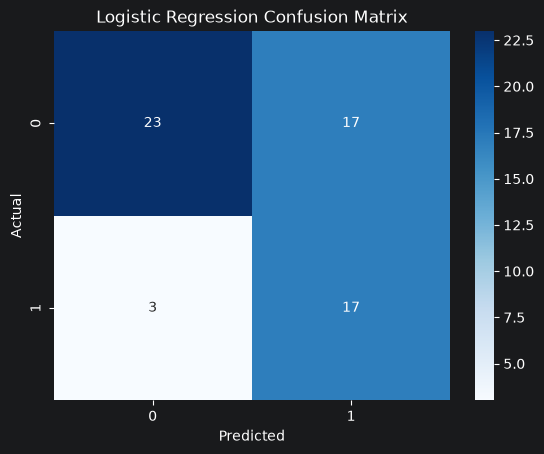

In [74]:
cm1 = pd.crosstab(y_test, y_pred_logreg)

sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues')

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

Support Vector Machine (SVM)

In [113]:
svm = SVC()

svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)

print("SVM Accuracy:", svm.score(X_test, y_test))

SVM Accuracy: 0.8333333333333334


<Figure size 500x400 with 0 Axes>

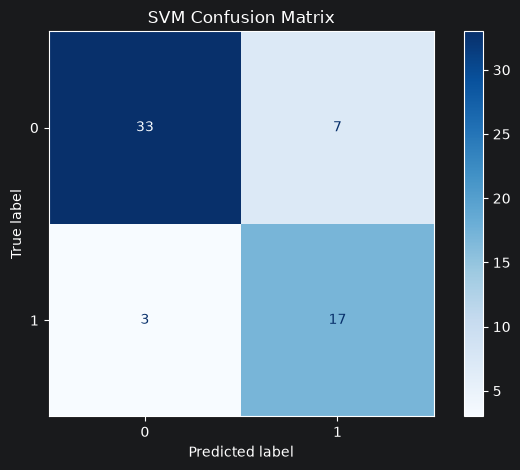

In [133]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


y_pred = svm.predict(X_test)


cm = confusion_matrix(y_test, y_pred)


plt.figure(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=svm.classes_)
disp.plot(cmap='Blues', values_format='d')

plt.title('SVM Confusion Matrix')
plt.tight_layout()
plt.show()


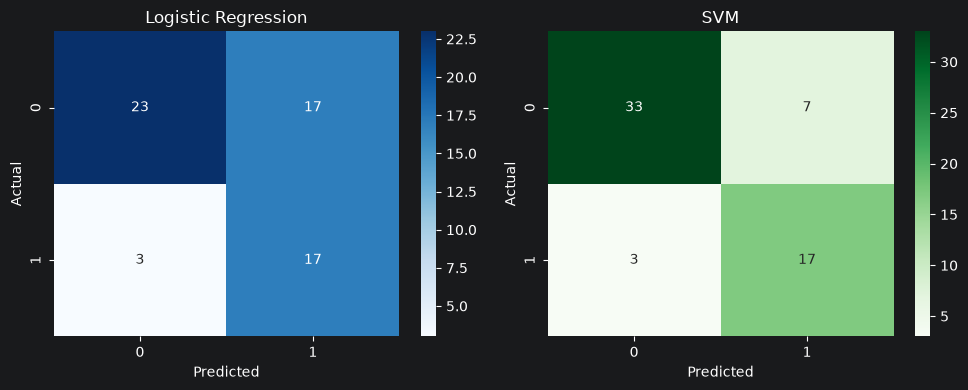

In [127]:
cm1 = pd.crosstab(y_test, y_pred_logreg)
cm2 = pd.crosstab(y_test, y_pred_svm)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues', ax=ax1)
ax1.set_title('Logistic Regression')
ax1.set_xlabel('Predicted')
ax1.set_ylabel('Actual')

sns.heatmap(cm2, annot=True, fmt='d', cmap='Greens', ax=ax2)
ax2.set_title('SVM')
ax2.set_xlabel('Predicted')
ax2.set_ylabel('Actual')

plt.tight_layout()
plt.show()

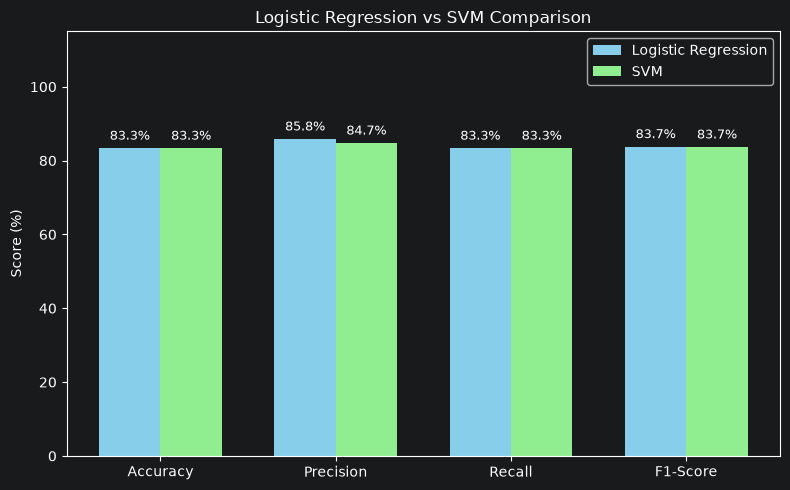

In [136]:
y_pred_logreg = logreg.predict(X_test)
y_pred_svm = svm.predict(X_test)


logreg_scores = [
    accuracy_score(y_test, y_pred_logreg) * 100,
    precision_score(y_test, y_pred_logreg, average='weighted') * 100,
    recall_score(y_test, y_pred_logreg, average='weighted') * 100,
    f1_score(y_test, y_pred_logreg, average='weighted') * 100
]

svm_scores = [
    accuracy_score(y_test, y_pred_svm) * 100,
    precision_score(y_test, y_pred_svm, average='weighted') * 100,
    recall_score(y_test, y_pred_svm, average='weighted') * 100,
    f1_score(y_test, y_pred_svm, average='weighted') * 100
]


metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))
bars1 = plt.bar(x - width/2, logreg_scores, width, label='Logistic Regression', color='skyblue')
bars2 = plt.bar(x + width/2, svm_scores, width, label='SVM', color='lightgreen')

plt.title('Logistic Regression vs SVM Comparison')
plt.ylabel('Score (%)')
plt.xticks(x, metrics)
plt.ylim(0, 115)
plt.legend()


for bar in bars1:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1.5, f'{yval:.1f}%', ha='center', va='bottom', fontsize=9)

for bar in bars2:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1.5, f'{yval:.1f}%', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()
